# **1. Perkenalan Dataset**


a. Nama Dataset: Bank Marketing Dataset

b. Sumber: [UCI Machine Learning Repository - Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing)
  
c. Jenis masalah: *Supervised Learning* - *Binary Classification*

d. Tujuan: Memprediksi apakah seorang nasabah akan berlangganan deposito berjangka (*term deposit*) berdasarkan karakteristik nasabah dan informasi kampanye pemasaran bank.

e. Deskripsi Dataset

Bank Marketing merupakan dataset yang berasal dari kampanye pemasaran langsung (direct marketing campaign) yang dilakukan oleh sebuah institusi perbankan di Portugal.

Kampanye pemasaran ini dilakukan melalui sambungan telepon dengan tujuan menawarkan produk deposito berjangka (term deposit) kepada nasabah.

Dataset ini berisi informasi mengenai karakteristik nasabah, kondisi keuangan, riwayat komunikasi, serta hasil dari kampanye pemasaran sebelumnya.

Dataset yang digunakan dalam proyek ini adalah bank-full.csv, yang terdiri dari 45.211 baris data dan 17 kolom.




# **2. Import Library**

Pada tahap ini, Anda perlu mengimpor beberapa pustaka (library) Python yang dibutuhkan untuk analisis data dan pembangunan model machine learning atau deep learning.

In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("semua library berhasil diimpor.")

semua library berhasil diimpor.


# **3. Memuat Dataset**

Pada tahap ini, Anda perlu memuat dataset ke dalam notebook. Jika dataset dalam format CSV, Anda bisa menggunakan pustaka pandas untuk membacanya. Pastikan untuk mengecek beberapa baris awal dataset untuk memahami strukturnya dan memastikan data telah dimuat dengan benar.

Jika dataset berada di Google Drive, pastikan Anda menghubungkan Google Drive ke Colab terlebih dahulu. Setelah dataset berhasil dimuat, langkah berikutnya adalah memeriksa kesesuaian data dan siap untuk dianalisis lebih lanjut.

Jika dataset berupa unstructured data, silakan sesuaikan dengan format seperti kelas Machine Learning Pengembangan atau Machine Learning Terapan

In [49]:
# Memuat file
df = pd.read_csv('bank_full_raw.csv', sep=';')

print("file berhasil di muat.")

file berhasil di muat.


In [50]:
# Menampilkan informasi mengenai dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [51]:
# Menampilkan 5 baris pertama pada dataset
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


# **4. Exploratory Data Analysis (EDA)**

Pada tahap ini, Anda akan melakukan **Exploratory Data Analysis (EDA)** untuk memahami karakteristik dataset.

Tujuan dari EDA adalah untuk memperoleh wawasan awal yang mendalam mengenai data dan menentukan langkah selanjutnya dalam analisis atau pemodelan.

4.1 Memahami sturktur dataset

In [52]:
# Melihat ringkasan statistik dari kolom yang berisi angka
display(df.describe())

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [53]:
# Melihat ringkasan statistik dari semua kolom, baik angka maupun teks/kategori
display(df.describe(include="all"))

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
count,45211.000000,45211,45211,45211,45211,45211.000000,45211,45211,45211,45211.000000,45211,45211.000000,45211.000000,45211.000000,45211.000000,45211,45211
unique,NaN,12,3,4,2,NaN,2,2,3,NaN,12,NaN,NaN,NaN,NaN,4,2
top,NaN,blue-collar,married,secondary,no,NaN,yes,no,cellular,NaN,may,NaN,NaN,NaN,NaN,unknown,no
freq,NaN,9732,27214,23202,44396,NaN,25130,37967,29285,NaN,13766,NaN,NaN,NaN,NaN,36959,39922
mean,40.936210,NaN,NaN,NaN,NaN,1362.272058,NaN,NaN,NaN,15.806419,NaN,258.163080,2.763841,40.197828,0.580323,NaN,NaN
std,10.618762,NaN,NaN,NaN,NaN,3044.765829,NaN,NaN,NaN,8.322476,NaN,257.527812,3.098021,100.128746,2.303441,NaN,NaN
min,18.000000,NaN,NaN,NaN,NaN,-8019.000000,NaN,NaN,NaN,1.000000,NaN,0.000000,1.000000,-1.000000,0.000000,NaN,NaN
25%,33.000000,NaN,NaN,NaN,NaN,72.000000,NaN,NaN,NaN,8.000000,NaN,103.000000,1.000000,-1.000000,0.000000,NaN,NaN
50%,39.000000,NaN,NaN,NaN,NaN,448.000000,NaN,NaN,NaN,16.000000,NaN,180.000000,2.000000,-1.000000,0.000000,NaN,NaN
75%,48.000000,NaN,NaN,NaN,NaN,1428.000000,NaN,NaN,NaN,21.000000,NaN,319.000000,3.000000,-1.000000,0.000000,NaN,NaN


 4.2 Memeriksa missing values dan duplikasi

In [54]:
# Memeriksa jumlah nilai kosong pada setiap kolom
missing_values = df.isnull().sum()

print("Jumlah missing values per kolom:")
display(missing_values.to_frame(name="missing_values"))

print("Total missing values:", df.isnull().sum().sum())

# Jumlah baris duplikat
print("Jumlah baris duplikat:", df.duplicated().sum())

Jumlah missing values per kolom:


,missing_values
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


Total missing values: 0
Jumlah baris duplikat: 0


4.3 Menganalisis distribusi target

In [55]:
# distribusi target
target_counts = df["y"].value_counts()
target_percent = df["y"].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    "jumlah": target_counts,
    "persentase": target_percent.round(2)
})

display(target_summary)

,jumlah,persentase
y,,
no,39922,88.3
yes,5289,11.7


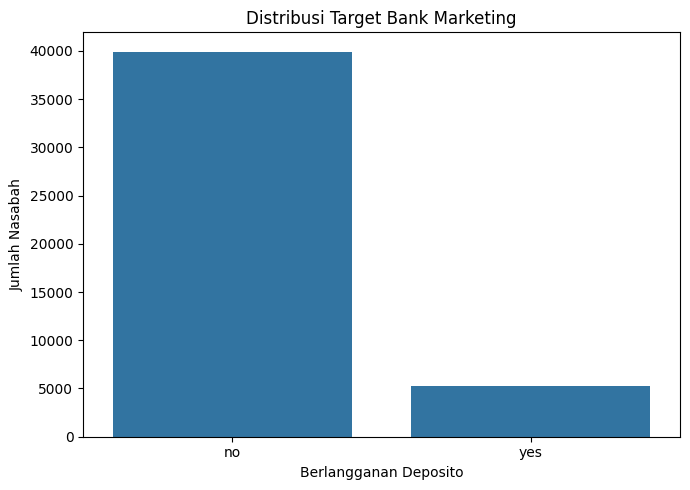

In [56]:
# Visualisasi distribusi target
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="y")
plt.title("Distribusi Target Bank Marketing")
plt.xlabel("Berlangganan Deposito")
plt.ylabel("Jumlah Nasabah")
plt.tight_layout()
plt.show()

4.4 Distribusi Fitur Numerik

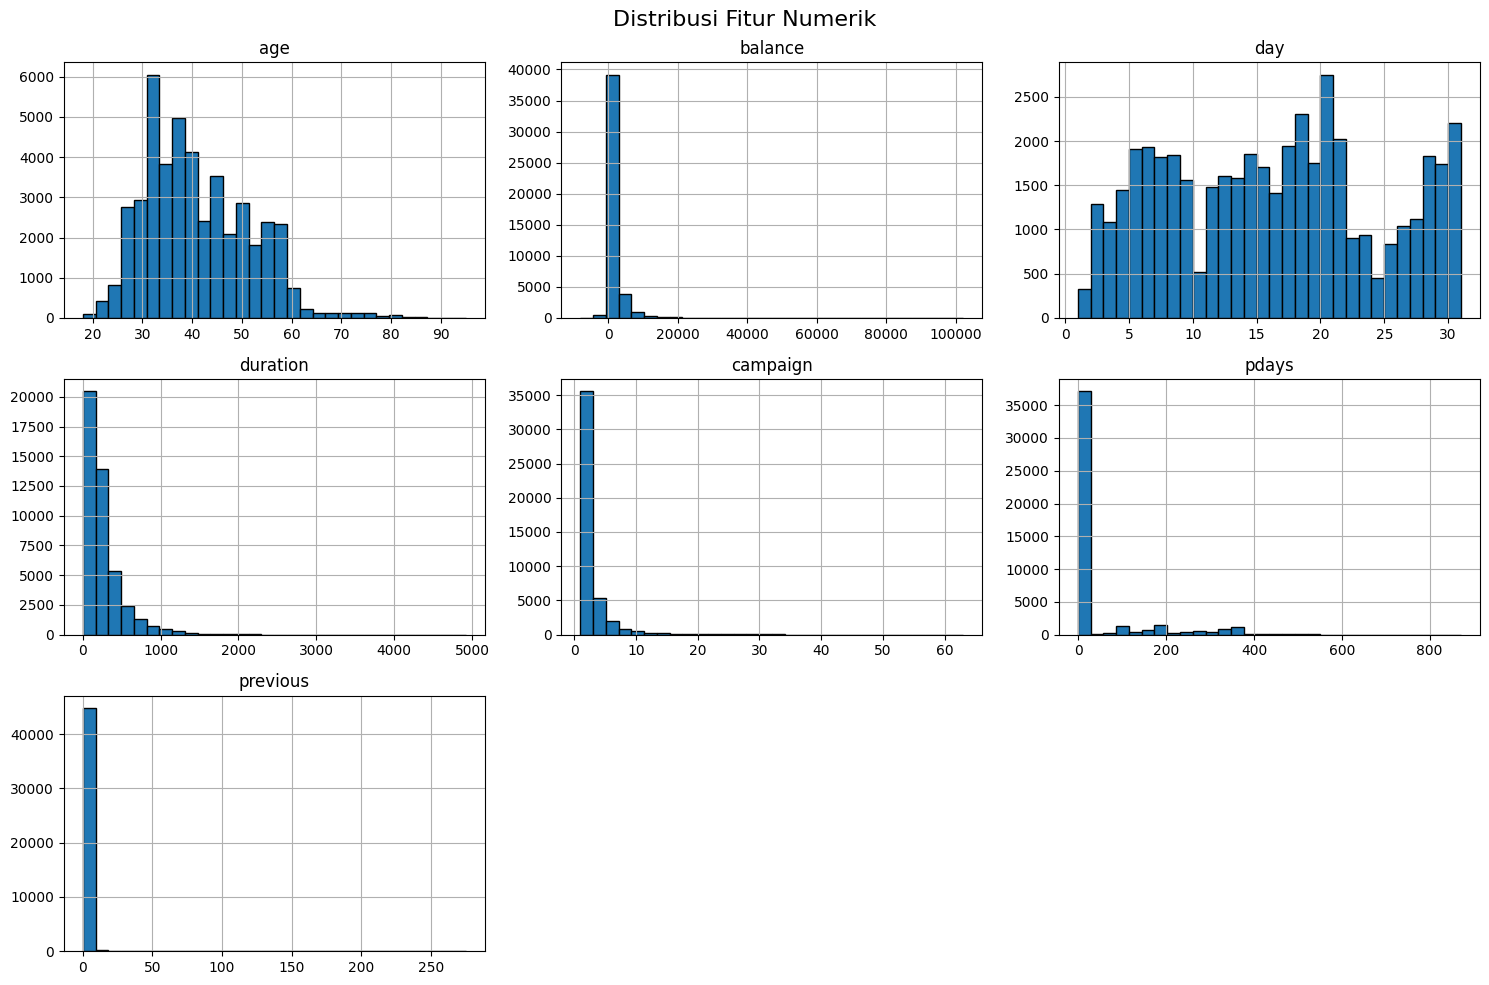

In [57]:
numeric_columns = [
    "age",
    "balance",
    "day",
    "duration",
    "campaign",
    "pdays",
    "previous"
]

df[numeric_columns].hist(
    figsize=(15,10),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribusi Fitur Numerik", fontsize=16)
plt.tight_layout()
plt.show()

4.5 Menganalisis fitur kategorikal

In [58]:
# Distribusi Firut Kategorikal
categorical_columns = [
    "job",
    "marital",
    "education",
    "default",
    "housing",
    "loan",
    "contact",
    "month",
    "poutcome"
]

for column in categorical_columns:
  print(f"\nDistribusi kategori: {column}")
  display(
      df[column]
      .value_counts(dropna=False)
      .to_frame(name="jumlah")
  )


Distribusi kategori: job


,jumlah
job,
blue-collar,9732
management,9458
technician,7597
admin.,5171
services,4154
retired,2264
self-employed,1579
entrepreneur,1487
unemployed,1303



Distribusi kategori: marital


,jumlah
marital,
married,27214
single,12790
divorced,5207



Distribusi kategori: education


,jumlah
education,
secondary,23202
tertiary,13301
primary,6851
unknown,1857


... (8 outputs left out)


Distribusi kategori: month


,jumlah
month,
may,13766
jul,6895
aug,6247
jun,5341
nov,3970
apr,2932
feb,2649
jan,1403
oct,738



Distribusi kategori: poutcome


,jumlah
poutcome,
unknown,36959
failure,4901
other,1840
success,1511


In [59]:
# Memeriksa kategori unknown

unknown_counts = (
    df.select_dtypes(include="object")
    .apply(lambda column: column.eq("unknown").sum())
)

print("Jumlah nilai 'unknown' per kolom:")
display(
    unknown_counts[unknown_counts > 0]
    .to_frame(name="jumlah_unknown")
)

Jumlah nilai 'unknown' per kolom:


,jumlah_unknown
job,288
education,1857
contact,13020
poutcome,36959


4.6 Memeriksa korelasi fitur numerik

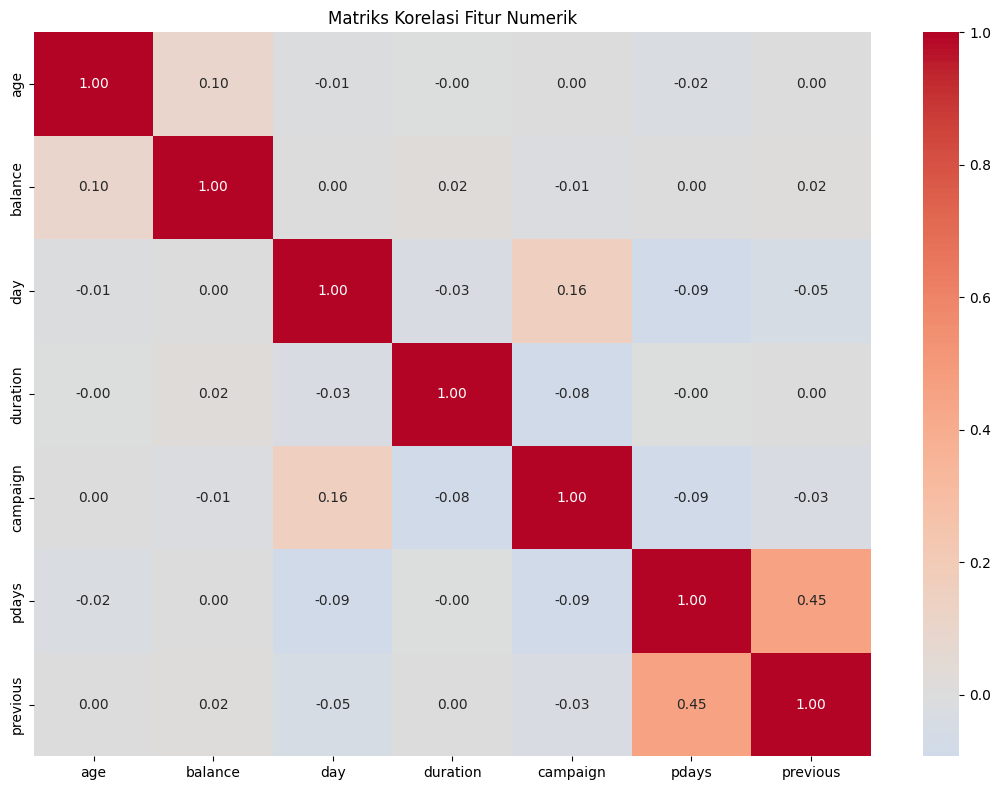

In [60]:
# Korelasi Fitur Numerik

correlation_matrix = df[numeric_columns].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Matriks Korelasi Fitur Numerik")
plt.tight_layout()
plt.show()

# **5. Data Preprocessing**

Pada tahap ini, data preprocessing adalah langkah penting untuk memastikan kualitas data sebelum digunakan dalam model machine learning.

Jika Anda menggunakan data teks, data mentah sering kali mengandung nilai kosong, duplikasi, atau rentang nilai yang tidak konsisten, yang dapat memengaruhi kinerja model. Oleh karena itu, proses ini bertujuan untuk membersihkan dan mempersiapkan data agar analisis berjalan optimal.

Berikut adalah tahapan-tahapan yang bisa dilakukan, tetapi **tidak terbatas** pada:
1. Menghapus atau Menangani Data Kosong (Missing Values)
2. Menghapus Data Duplikat
3. Normalisasi atau Standarisasi Fitur
4. Deteksi dan Penanganan Outlier
5. Encoding Data Kategorikal
6. Binning (Pengelompokan Data)

Cukup sesuaikan dengan karakteristik data yang kamu gunakan yah. Khususnya ketika kami menggunakan data tidak terstruktur.

5.1 Menentukan fitur dan target

In [61]:
# Memisahkan Fitur dan Target

# Menyalin dataset agara data asli tetap aman
data = df.copy()

# Menghapus duration untuk menghindari data leakage
data = data.drop(columns=["duration"])

# Memisahkan fitur dan target
X = data.drop(columns=["y"])
y = data["y"].map({
    "no": 0,
    "yes":1
})

print("Jumlah fitur:", X.shape[1])
print("Jumlah target:", y.shape[0])

Jumlah fitur: 15
Jumlah target: 45211


5.2 Mengidentifikasi fitur numerik dan kategorikal

In [62]:
# Mengidentifikasi Jenis fitur

# Mengambil kolom numerik
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Mengambil kolom kategorikal
categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Fitur Numerik:")
print(numeric_features)

print("\nFitur Kategorikal:")
print(categorical_features)

print("\nJumlah fitur numerik:", len(numeric_features))
print("Jumlah fitur kategorikal:", len(categorical_features))

Fitur Numerik:
['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

Fitur Kategorikal:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Jumlah fitur numerik: 6
Jumlah fitur kategorikal: 9


5.3 Membagi data training dan testing

In [63]:
# Membagi Dataset

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing:", X_test.shape[0])

print("\nDistribusi target training:")
print(y_train.value_counts(normalize=True) * 100)

Jumlah data training: 36168
Jumlah data testing: 9043

Distribusi target training:
y
0    88.301814
1    11.698186
Name: proportion, dtype: float64


5.4 Encoding dan standardisasi

In [64]:
from sklearn import preprocessing
# Encoding dan Standardisasi

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Pipeline preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            StandardScaler(),
            numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

# Parameter preprocessing dari data training
X_train_processed = preprocessor.fit_transform(X_train)

# Menerapkan preprocessing yang sama pada data testing
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing berhasil.")
print("Ukuran data training:", X_train_processed.shape)
print("Ukuran data testint:", X_test_processed.shape)

Preprocessing berhasil.
Ukuran data training: (36168, 50)
Ukuran data testint: (9043, 50)


**Kesimpulan Data Preprocessing**

Berdasarkan tahapan eksplorasi dan preprocessing yang telah dilakukan, diperoleh hasil sebagai berikut:

1. Dataset Bank Marketing memiliki 45.211 observasi dan 17 kolom.
2. Tidak ditemukan *missing values* maupun data duplikat.
3. Kolom *duration* dihapus untuk menghindari data *leakge* karena tidak tersedia sebelum proses pemasaran dilakukan.
4. Target y dikonversi menjadi nilai numerik, yaitu 0 untuk *no* dan 1 untuk *yes*.
5. Fitur katergorikal diproses menggunakan *One-Hot Encoding*.
6. Fitur numerikal distandardisasi menggunakan *StandardScaler*.
7. Fitur numerik menjadi **80%** data *training* (36.168 observasi) dan **20%** data *testing* (9.043 observasi).
8. Hasil *preprocessing* menghasilkan 50 fitur.
9. Tidak ditemukkan *missing values* setelah *preprocessing*.

Dengan demikian, dataset telah berhasil melalui tahapan eksperimen dan *preprocessing* secara manual serta siap digunakan untuk pembangunan model *Machine Learning*.